In [20]:
from tqdm import trange
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

## Oppgave 3

Starter med å introdusere generaliserte funksjoner for bruk i oppgave 3. Merk at selv om diskusjon i 1c, gjør at man med god tilnærming kan tilnærme partiklene vil følge den negative gradienten til potensialet, og neglisjere statistiske effekter for store verdier av $k \beta$ er dette ikke implementert. Selv om dette ville kunne gi høyere ytelse ville dette stride mot hensikten til oppgaven, ettersom formålet er å se hvordan disse faktorene påvirker resultatet, og ikke rask kjørehastighet.

Videre er også $\beta$ trukket inn i konstanten $k$, for enkelhets skyld, siden $k \beta$ opptrer som konstant i alle oppgavene, og potensialene avhenger lineært av k. For enkelhetskyld er funksjonene definert på en slik måte at ikke-spesifiserte parametre settes lik parameterne i oppgave 3a, med $\alpha = 0.8$. Der gloable variabler kun benyttes innefor sin kodeblokk, eller tilsvarer lokale variabler er variabelnavn gjenbrukt, mens de som benyttes i flere kodedblokker er markert med oppgavenummer. Der oppgaven spesifiserer at det skal brukes verdier som er jevnt fordelt mellom to verdier, er det lagt vekt på at punktene skal være jevnt fordelt, der hvor tallverdiene oppgitt i utgangspunktet ville ført til flyttall for heltallsvariable slik som $T_p$ dersom man inkluderer begge endepunkt.

In [ ]:
def V_1(
        x : np.ArrayLike,
        k : float       = 1000,
        N_x : float     = 100,
        alpha : float   = 0.8
        ) -> np.ArrayLike : 
    """
    params:
        x:      Arraylike med heltallsposisjoner
        k:      konstant som tilsvarer k * beta
        N_x:    antall binding sites i én periode
        alpha:  konstant
    return:
        pot:    Potentialet V_1
    """
    x_modN =x%N_x

    pot = -k*(x_modN-N_x)/((1 - alpha)*N_x)
    pot[x_modN <= alpha * N_x]  =(k * x_modN/(alpha * N_x))[x_modN <= alpha * N_x]

    return pot
    
def V_2(x, *args) -> int:
    return np.zeros_like(x)

def probabilities(
        V : function,
        x_0 : np.ArrayLike,
        k : float,
        N_x : float,
        alpha : float
        ) -> tuple[np.ndarray, np.ndarray] : 
    """
    params:
        V:    potensialfunksjonen sannsynlighetene beregnes ut ifra
        x_0:      ArrayLike med posisjoner, hvis sannsynlighet for forflyttning skal finnes
        *args:  parameterene som potensialet tar inn
    returns:
        
    """

    pot_minus = V(x_0 - 1, k, N_x, alpha)
    pot_zero  = V(x_0, k, N_x, alpha)
    pot_plus  = V(x_0 + 1, k, N_x, alpha)

    p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1
    p_plus = (1 + np.exp(pot_plus - pot_zero) + np.exp(pot_plus - pot_minus))**-1
    
    return p_minus, p_plus

def simulate3(
        startPositions : np.ndarray = np.array([]),
        alpha : float  = 0.8, 
        T_p : int = 500, 
        N_x : int = 100, 
        N_p : int = 1200,
        k : int  = 1000,
        spatialPeriods : int  = 2,
        cycles : int = 10,
        startV_2 : bool = False
        )-> tuple[np.ndarray, np.ndarray, list]:
    """
    params:
        startPositions: array over startposisjoner, hvis None brukes fylles alle posisjoner
        alpha: konstant, forskyver potensialet
        T_p: tidsperiode for en halv syklus
        N_x: romlig periode for potensial
        N_p antall partikler, rundes av til multiplum av antall festepunkter
        k: samlet konstant lik k * beta
        spatialPeriods: antall romlige perioder, gir antall festepunkter som N_p * spatialPeriods
        cycles: antall sykluser som skal simuleres
        startV_2: hvis True starter blir V_2 det første potensialet
    returns:
        x: array med sluttposisjoner
        currents: array
        XX: matrise med posisjoner for hvert tidssteg slik at x(t) = X[t]
    """

    
    N = N_x * spatialPeriods #antall festepunkter
    XX = [] 
    x_ref : np.ndarray  = np.arange(N) #referansearray for x-aksen. Verdier samsvarer med indeks for referansearrayer
    
    if len(startPositions) == 0:
        startPositions = x_ref

    x_0 : np.ndarray = np.asarray([i for i in startPositions for _ in range(N_p//len(startPositions))]) #array med alle partikler
    XX.append(x_0)

    p_1 = probabilities(V_1, x_ref, k, N_x, alpha)
    p_2 = probabilities(V_2, x_ref, k, N_x , alpha)

    pm_tup = (p_1[0], p_2[0])
    pp_tup = (p_1[1], p_2[1])

    n = np.zeros_like(x_0)

    currents = np.zeros(cycles)
    for c in trange(2 * cycles, ascii = True, desc  = "runnning half-cycles"):
        pm_ref  = pm_tup[c%2 - int(startV_2)]
        pp_ref =  pp_tup[c%2 - int(startV_2)]

        for t in range(T_p):
            x = x_0%N
            pm = np.asarray([pm_ref[i] for i in x]) # sannsynlighet for å gå til venstre for alle partikler
            pp = np.asarray([pp_ref[i] for i in x]) # sannsynlighet fro å gå til høyre for alle partikler

            r = np.random.rand(N_p)
            x[r < pm] -= 1
            x[1 - pp < r] += 1

            n += x - x_0%N
            x_0 = x

            XX.append(x_0)
            
        if c%2:
            currents[c//2] = np.mean(n)/(2 * T_p)
            n = np.zeros_like(x)

    return x, currents, XX


### 3a

simulering med $\alpha = 0.8$.

In [22]:
x, currentsA1, XX = simulate3(alpha = 0.8)

for i in range(len(currentsA1)):
    print(f"{i}: {currentsA1[i]:.6f}")

runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.38it/s]

0: -0.028928
1: -0.013468
2: -0.013417
3: -0.013537
4: -0.014078
5: -0.011901
6: -0.012071
7: -0.013014
8: -0.013645
9: -0.013461


Man får netto strøm mot venstre ettersom partiklene samles opp i minimumspunktene til $V_1$, og deretter blir eksitert til tilstand $V_2$, hvor de diffunderer. Ettersom nærmeste lokale maksimum for partiklene er det til venstre for der de ble samlet opp, er det flere partikler som forflytter seg forbi dette, enn det er partikler som forflytter seg forbi nærmeste lokale maksimum mot høyre. Når de deeksiteres vil disse partiklene samles opp i et annet lokalt minimum, noe som fører til netto strøm.

Dette forklarer hvorfor strømmen er større til å start med, ettersom de da var uniformt fordelt, og ikke fordelt rundt minimumspunktene slik som i resten av syklusene.

In [23]:
x, currentsA2, XX = simulate3(alpha = 0.1)

for i in range(len(currentsA2)):
    print(f"{i}: {currentsA2[i]:.6f}")

runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.60it/s]

0: 0.039681
1: 0.028422
2: 0.029337
3: 0.029077
4: 0.027093
5: 0.027845
6: 0.029239
7: 0.029165
8: 0.029756
9: 0.027835


For $\alpha = 0.1$ har vi en tilsvarende situasjon, men hvor lokale mimium ligger rett til venstre for lokale maksimum, og man får dermed strøm mot høyre. Det ligger nærmere enn for $\alpha = 0.8$ så derfor er strømmen større.

### 3b

In [24]:
timePeriodList = [i for i in range(1, 1001, 20)]   
startPositions = np.array([0, 100])
n = len(timePeriodList)
avgCurrentB = np.zeros(n)
N_x = 100

for i in range(n):
    x, currents, XX = simulate3(
        T_p = timePeriodList[i],
        cycles = 1,
        alpha = 0.8,
        N_p = 40 * N_x,
        N_x = N_x,
        startPositions = startPositions,
        startV_2=True)
    
    avgCurrentB[i] = np.mean(currents)

runnning half-cycles: 100%|##########| 2/2 [00:02<00:00,  1.40s/it]


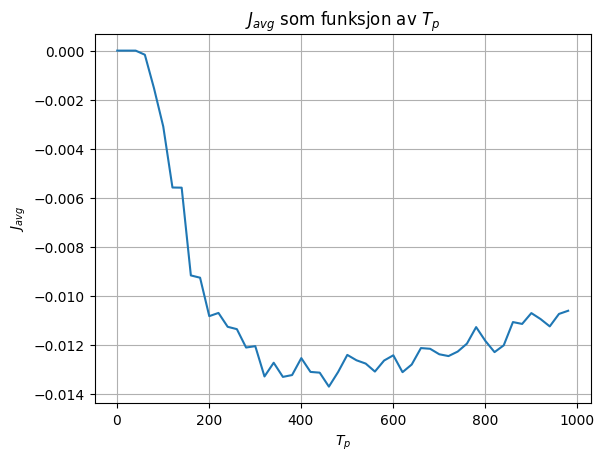

In [25]:
plt.plot(timePeriodList, avgCurrentB, label = "$k_b \beta = 1000")
plt.title("$J_{avg}$ som funksjon av $T_p$")
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.grid()
plt.show()

Strømmen mot venstre øker for økende verdier av $T_p$. Dette samvarer med lengre tid for diffusjon, slik at flere partikler beveger forbi nærmeste lokale maksimum for $V_1$. I tillegg vil det for $T_p < \alpha N_x = 80$ ($1-\alpha$ må brukes istedenfor $\alpha$ dersom $\alpha > 0.5$) ikke være nok tid for alle partiklene til å samles i sitt lokale minimumspunkt i løpet av tidsperioden med potensialet $V_1$. Dette gjør strømmen i starten øker rast med økende tidsperiode, ettersom de både diffunderer mer, og forflytter seg lengre etter diffusjon. Når tidsperioden er tilstrekkelig høy, vil partiklene diffundere tregere, ettersom de allerede er utspredt, og alle partiklene vil samles opp i lokale minimumspunkt i løpet av den deeksiterte perioden. Dermed avtar strømmen mot venstre ved økning av $T_p$, ettersom partiklene ikke beveger seg lengre per periode, mens periodene fortsatt blir lengre.



### 3c

Definerer først en funksjon for den analytiske strømmen som funksjon av de ingående variablene, ved hjelp av scipy.special.erfc.

In [26]:
def analCurrent(
        alpha : np.ndarray,
        N_x : int,
        T_p : np.ArrayLike):
    return N_x/(4*T_p) * (erfc(alpha*N_x/2 * np.sqrt(3/T_p)) - erfc((1-alpha)*N_x/2 * np.sqrt(3/T_p)))

Ettersom den analystiske løsningen baserer seg på at partiklene i utgangspunktet er fordelt som $\delta(x),$ gir det mening å bruke liknende betingelser som i oppgave 3b, hvor partiklene starter samlet og starter i den eksiterte tilstanden med $V(x, t = 0) = V_2(x)$. Kjøretid påvirkes først og fremst av antall partikler i systemet, og strømmen er uavhengig av hvilket loklt mimimum partiklene starter i, så andre variabler som ikke er spesifisert i oppgaven kan velges ganske fritt. Velger liknende som i tidligere oppgaver for enkelhets skyld.

In [ ]:
n = 50

alphaArr = np.linspace(0.001, 0.999, n) 
startPositions = np.array([0, 100])
avgCurrentC = np.zeros(n)

for i in range(n):
    x, currents, XX = simulate3(
        T_p = 500,
        cycles = 1,
        alpha = alphaArr[i],
        N_x  = 100,
        N_p = 1200,
        k = 1000,
        startPositions = startPositions,
        startV_2=True)
        
    avgCurrentC[i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:46: RuntimeWarning: overflow encountered in exp
  p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.85it/s]
C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:47: RuntimeWarning: overflow encountered in exp
  p_plus = (1 + np.exp(pot_plus - pot_zero) + np.exp(pot_plus - pot_minus))**-1
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.51it/s]


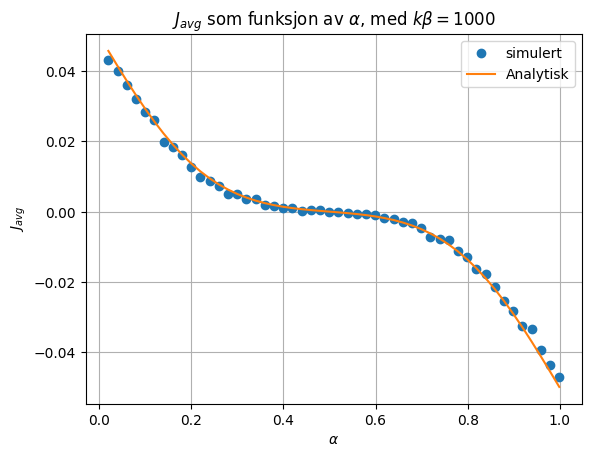

In [34]:
avgAnalCurrentC = analCurrent(alphaArr, N_x = 100, T_p = 500)

plt.figure()
plt.plot(alphaArr, avgCurrentC, 'o', label = "simulert")
plt.plot(alphaArr, avgAnalCurrentC, label = "Analytisk")
plt.grid()
plt.legend()
plt.title("$J_{avg}$ som funksjon av $\\alpha$, med $k\\beta = 1000$")
plt.xlabel("$\\alpha$")
plt.ylabel("$J_{avg}$")
plt.show()

Liten $\alpha$ gir strøm mot høyre, og stor $\alpha$ gir strøm mot venstre. Der strømmen varierer mer lenger vekk ifra $\alpha = 0.5$. Dette skyldes at partiklene diffunderer mest der de er konsentrert slik at flere partikler diffunderer forbi lokalt makismum dersom det ligger nærmere korresponderende lokalt mimium, som er utgangspunktet før diffusjon. På liknende måte vil forskyving av normalfordelingen med tanke på maksiumspunktet ha mer å si nærmere punktet, ettersom er normalfordelingen har høyere tetthet nær sentrum. Ser at de to ulike løsningene er koherente.

### 3d

In [ ]:
n = 50
kArr = np.array([0.01, 1, 2, 3, 5, 10])
m = len(kArr)

N_x = 100
N_p = 12 * N_x
T_p = 500


alphaArr = np.linspace(0.001, 0.999, n)
startPositions = np.array([0, 100])
avgCurrentD = np.zeros((m, n))

for i in range(n):
    for j in range(m):
        x, currents, XX = simulate3(
            T_p = T_p,
            cycles = 1,
            alpha = alphaArr[i],
            N_x  = N_x,
            N_p = N_p,
            k = kArr[j],
            startPositions = startPositions,
            startV_2=True)
        
        avgCurrentD[j][i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:18: RuntimeWarning: divide by zero encountered in divide
  pot = -k*(x_modN-N_x)/((1 - alpha)*N_x)
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.63it/s]


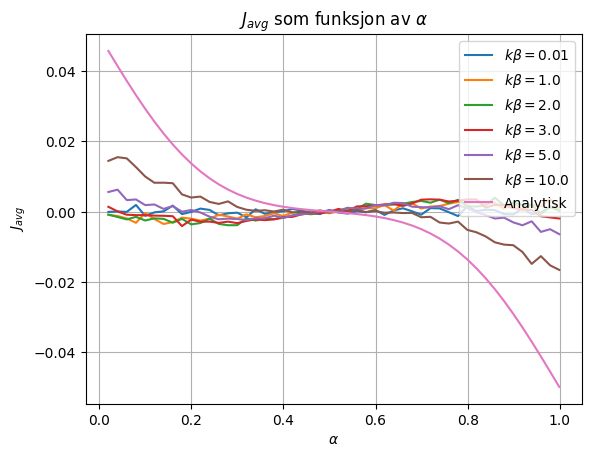

In [ ]:
avgAnalCurrentD = analCurrent(alphaArr, N_x = 100, T_p = 500)

plt.figure()
for j in range(m):
    plt.plot(alphaArr, avgCurrentD[j], label = f"$k \\beta = {kArr[j]}$")
plt.plot(alphaArr, avgAnalCurrentD, label = "Analytisk")
plt.grid()
plt.legend(loc = "upper right")
plt.title("$J_{avg}$ som funksjon av $\\alpha$")
plt.xlabel("$\\alpha$")
plt.ylabel("$J_{avg}$")
plt.show()

Alle verdiene for $k \beta$ gir stort avik fra den analytiske løsningen, og dette skyldes nok at potensialgradientet ikke er bratt nok for at antakelsen om at alle partiklene ender opp i potensialminima er gyldig.

For $k \beta = 0.01$ er det i praksis kun diffusjon som spiller en rolle for begge potensialene ettersom den termiske energien er mye større enn potensialgradienten. Dermed skyldes variasjonene i strøm trolig kun støy.

For $k \beta \in {1,2,3}$ får man en svak strøm i motsatt retning av den predikert av den analytiske løsningen. Grunnen til dette er at i disse tilfellene har partiklenes posisjoner mindre å si, ettersom det er brattheten til potensialene som har mer å si for hvor langt partiklene beveger seg, og den bratteste potensialgradienten fører partiklene i motsatt retning av den predikerte strømmen, mens den slake potensialgradienten ikke påvirker partiklene nok, selv om den har flere partikler på seg.

For $k \beta = 5,10$ går strømmen igjen i riktig retning, som tyder på at det ved høyere verdier for $T_p$ trolig vil være nærmere den analytsike løsningen, men at tidsperioden ikke er stor nok til at partiklene rekker å samles, eller at de ikke sentreres fullstendig i mimimumspunktet.

### 3e

Velger å ta gjennomsnittet over 10 tidsykluser, siden parameterene gitt i oppgaven gir veldig varierende målinger som er vanskelige og tolke, og koden er rask nok. Ettersom $T_p \gg \alpha N_x$ og $k \beta = 1000$ tar koden under utganspunkt i at partiklene ender opp i lokale minimum etter hver syklus, for å slippe å tilbakestille partiklene for hver syklus.

In [52]:
timePeriodList = [i for i in range(80, 1500, 71)]   
startPositions = np.array([0, 100])
n = len(timePeriodList)
avgCurrentE = np.zeros(n)
N_x = 10
print(f"n = {n}")

for i in range(n):
    x, currents, XX = simulate3(
        T_p = timePeriodList[i],
        cycles = 10,
        alpha = 0.8,
        N_p = 40*N_x,
        N_x = N_x,
        startPositions = startPositions,
        startV_2=True)
    
    avgCurrentE[i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:46: RuntimeWarning: overflow encountered in exp
  p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1


n = 20


runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.02it/s]


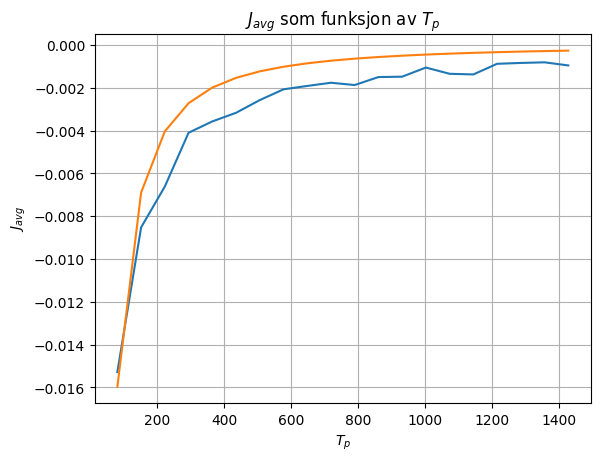

In [53]:
avgAnalCurrentE  = analCurrent(alpha = 0.8, N_x = 10, T_p = np.array(timePeriodList))

plt.plot(timePeriodList, avgCurrentE)
plt.plot(timePeriodList, avgAnalCurrentE)
plt.title("$J_{avg}$ som funksjon av $T_p$")
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.grid()
plt.show()

Den analytiske løsningen gir en god tilnærming for lave verdier $T_p$, men går raskere mot null en simulerte løsningen.Analytisk antas litt forenklet at man maksimalt kan få en strøm der partiklene flytter seg $N_x$ posisjoner i én retning per syklus, uvahengig av lengden på tidsperioden. For modellen vår vil partiklene derimot kunne diffundere over flere tidsperioder før de deeksiteres, og strømmen vil dermed gå saktere mot null. Dette fordi det fører til at sentreringen av fordelingen har mer å si.

### 3f
Ettersom den analytiske funksjonen tar utgangspunkt i et uendelig antall partikler, vil partiklene være fordelt etter sannsynlighetsfordelingen, mens det med et endelig antall partikler vil kunne variere hvor mange partikler som havner på hver sin side av et lokalt maksimum. Dette er mer sannsynlig for små/store $\alpha$, ettersom det er flere partikler i nærheten av lokale maksimum for slike $\alpha$. 

Dersom $k \beta$ eller $T_p$ i forhold til $N_x$ ikke er store nok til at alle partiklene rekker å nå sine lokale minimum innen tidsperioden for $V_1$ er omme, vil dette kunne gi store avvik for strømmen, ettersom den analytiske løsningen baserer seg på at alle partiklene beveger seg til sitt lokale minimum. For $k \beta < \infty$  vil det også være en endelig sannsynlighet for at partiklene ikke befinner seg nøyaktig i minimumspunktet etter endt tidsperiode, siden $p_-,p_+ > 0$. Dette gir neppe store avvik fra den analytiske løsningen for tilstrekkelig stor $k\beta$ ettersom dette gjelder få partikler, med lite avvik i posisjon, men kan gi forskyving av hvor partiklene sentreres for små verdier av $k \beta$, grunnet ulik bratthet, og kan også føre til strøm i motsatt retning dersom den ene retningen er tilstrekkelig bratt i forhold til den andre, og tidsperioden ikke er lang nok til at partiklene senterers i begge retninger.

Videre antar en analytiske løsningen at én gitt partikkel aldri beveger seg mer enn $N_x$ til høyre eller venstre i løpet av en periode. Dette fører til at ved nok utspredning av partikkler får man netto null strøm, ettersom nesten alle partiklene har beveget seg eneten til høyre eller venstre. I realiteten kan partiklene bevege seg over flere perioder, og vil fortsette å være sentrert mer mot én side. Slik vil netto forflytning ikke gå mot null slik som det analytiske tilfellet. Ettersom strøm er nettoforflytning per tid, vil dette også gi høyere strøm. 